# Model Development — TrOCR + mT5 Pipeline
**Student:** [Tên / MSSV]

## Tổng quan pipeline
```
context text
    → render PIL image (white on black)        [non-text representation]
    → TrOCRProcessor → pixel_values tensor     [ViT input format]
    → TrOCR ViT encoder → hidden states        [visual features]
    → Projection bridge (768→512)              [align spaces]
    → mT5 decoder → target token IDs          [text generation]
    → tokenizer.decode → predicted string
    → render_target_to_image()                 [post-processing]
    → image_to_pixels()                        [submission format]
```

**EDA insights được áp dụng:**
- `max_target_len=128` — cover German outliers (max 156 chars)
- `min_target_len=6` — shortest target = 16 chars ≈ 6 tokens
- 86.2% mid-word splits → decoder cần handle incomplete context word
- `max_width` continuous → model dùng `width_proj` để condition, không lookup


## 0. Setup & Imports

In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
from transformers import TrOCRProcessor, AutoTokenizer

# Import project modules
from config import get_config, LANG2ID, ID2LANG
from model import TrOCRmT5Model
from dataset import PixelTextDataset
from utils import render_text_to_image, render_target_to_image, image_to_pixels

config = get_config()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'Config max_target_len: {config["max_target_len"]}')
print(f'Config min_target_len: {config["min_target_len"]}')
print(f'Config batch_size:     {config["batch_size"]}')


c:\Users\Vanh\anaconda3\envs\transformer-gpu\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Config max_target_len: 128
Config min_target_len: 6
Config batch_size:     8


## 1. Model Architecture

### Tại sao chọn TrOCR + mT5?

**TrOCR encoder (ViT-base):**
- Pretrained trên rendered text images → đã học visual features của chữ viết
- Input: pixel_values (3, 384, 384) — context được render thành ảnh
- Output: 577 patch embeddings × 768 dims (1 CLS + 576 patches)
- Đây là "non-text representation" hợp lệ theo yêu cầu đề bài

**Projection bridge (768→512):**
- Map encoder space (TrOCR, 768-dim) sang decoder space (mT5, 512-dim)
- Two-layer MLP + GELU + LayerNorm + **residual skip connection**
- Residual skip quan trọng: không có nó, MLP có thể collapse tất cả vectors về cùng một điểm

**mT5-small decoder:**
- Pretrained multilingual seq2seq — hiểu 5 ngôn ngữ trong dataset
- Cross-attention attend vào encoder memory để generate target tokens
- lm_head: 512 → 250,112 (vocab size)

**Language + Width conditioning:**
- `lang_embed`: embedding cho 5 ngôn ngữ, cộng vào memory
- `width_proj`: MLP(1→512) từ normalized max_width, cộng vào memory
- EDA: test có 51 max_width unseen → cần continuous projection, không lookup


In [2]:
# Load model và hiển thị architecture
trocr_processor = TrOCRProcessor.from_pretrained(config['encoder_name'])
mt5_tokenizer   = AutoTokenizer.from_pretrained(config['mt5_model'])

model = TrOCRmT5Model(config).to(device)

# Parameter count breakdown
enc_p  = sum(p.numel() for n, p in model.named_parameters() if 'encoder' in n)
dec_p  = sum(p.numel() for n, p in model.named_parameters()
             if 'decoder' in n or 'lm_head' in n)
proj_p = sum(p.numel() for n, p in model.named_parameters()
             if any(k in n for k in ('proj', 'lang_embed', 'width_proj', 'memory')))
total  = sum(p.numel() for p in model.parameters())

print('=' * 55)
print('MODEL PARAMETER COUNT')
print('=' * 55)
print(f'  TrOCR ViT encoder:   {enc_p:>12,}  ({enc_p/total*100:.1f}%)')
print(f'  mT5 decoder + head:  {dec_p:>12,}  ({dec_p/total*100:.1f}%)')
print(f'  Projection bridge:   {proj_p:>12,}  ({proj_p/total*100:.1f}%)')
print(f'  Total:               {total:>12,}')
print('=' * 55)
print(f'  mT5 vocab size:      {model.mt5_config.vocab_size:>12,}')
print(f'  mT5 d_model:         {model.mt5_config.d_model:>12,}')
print(f'  mT5 decoder layers:  {model.mt5_config.num_layers:>12,}')
print(f'  TrOCR patch size:    {"16×16 px":>12s}')
print(f'  TrOCR input size:    {"384×384 px":>12s}')
print(f'  TrOCR num patches:   {"576 + 1 CLS":>12s}')
print('=' * 55)


Loading weights: 100%|██████████| 478/478 [00:00<00:00, 6621.87it/s]
VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Loading weights: 100%|██████████| 192/192 [00:00<00:00, 29129.22it/s]
The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


MODEL PARAMETER COUNT
  TrOCR ViT encoder:     86,653,440  (23.4%)
  mT5 decoder + head:   281,293,504  (76.0%)
  Projection bridge:      2,564,353  (0.7%)
  Total:                369,920,705
  mT5 vocab size:           250,112
  mT5 d_model:                  512
  mT5 decoder layers:             8
  TrOCR patch size:        16×16 px
  TrOCR input size:      384×384 px
  TrOCR num patches:    576 + 1 CLS


## 2. Dataset & Preprocessing

### Pipeline chuyển đổi text → non-text representation

Mỗi sample trong `PixelTextDataset`:
1. Lấy `context` text và `max_width` từ CSV
2. **Render** context → PIL grayscale image (white text on black)
3. **Pad to square** → giữ aspect ratio, pad bằng black pixels
4. **Convert RGB** → TrOCR processor yêu cầu 3 channels
5. **TrOCR feature extractor** → resize 384×384, normalize → `pixel_values` (3, 384, 384)
6. Encode target text → `labels` (token IDs, pad=-100)

Bước 2–5 là "non-text representation" theo yêu cầu đề.


In [3]:
from sklearn.model_selection import train_test_split

# Load data
df = pd.read_csv(config['train_file'])
try:
    train_df, val_df = train_test_split(
        df, test_size=config['val_split'],
        stratify=df['language'], random_state=42
    )
except Exception:
    val_df = df.sample(frac=config['val_split'], random_state=42)
    train_df = df.drop(val_df.index)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print(f'Train: {len(train_df)} samples')
print(f'Val:   {len(val_df)} samples')
print(f'Train lang dist: {train_df["language"].value_counts().to_dict()}')
print(f'Val   lang dist: {val_df["language"].value_counts().to_dict()}')

# Build datasets
train_ds = PixelTextDataset(train_df, trocr_processor, mt5_tokenizer, config)
val_ds   = PixelTextDataset(val_df,   trocr_processor, mt5_tokenizer, config)

# Inspect one sample
s = train_ds[0]
print(f'\nSample keys: {list(s.keys())}')
print(f'pixel_values shape: {s["pixel_values"].shape}  dtype={s["pixel_values"].dtype}')
print(f'pixel_values range: [{s["pixel_values"].min():.3f}, {s["pixel_values"].max():.3f}]')
print(f'labels shape:       {s["labels"].shape}  dtype={s["labels"].dtype}')
lbl = s['labels'].clone(); lbl[lbl == -100] = mt5_tokenizer.pad_token_id
print(f'target decoded:     "{mt5_tokenizer.decode(lbl, skip_special_tokens=True)[:70]}"')
print(f'lang_id:            {s["lang_id"].item()} ({ID2LANG[s["lang_id"].item()]})')
print(f'max_width (norm):   {s["max_width"].item():.4f}  (raw ≈ {s["max_width"].item()*1600:.0f}px)')


Train: 1305 samples
Val:   145 samples
Train lang dist: {'English': 652, 'Italian': 172, 'German': 172, 'Spanish': 162, 'French': 147}
Val   lang dist: {'English': 73, 'Italian': 19, 'German': 19, 'Spanish': 18, 'French': 16}

Sample keys: ['pixel_values', 'lang_id', 'max_width', 'labels']
pixel_values shape: torch.Size([3, 384, 384])  dtype=torch.float32
pixel_values range: [-1.000, 1.000]
labels shape:       torch.Size([128])  dtype=torch.int64
target decoded:     "wanteconomic security and good salaries."
lang_id:            0 (English)
max_width (norm):   0.2275  (raw ≈ 364px)


[English]
Context (last 60 chars): ...e look for internships or placements to learn. Families want
Target:                  economic security and good salaries.
max_width: 364px


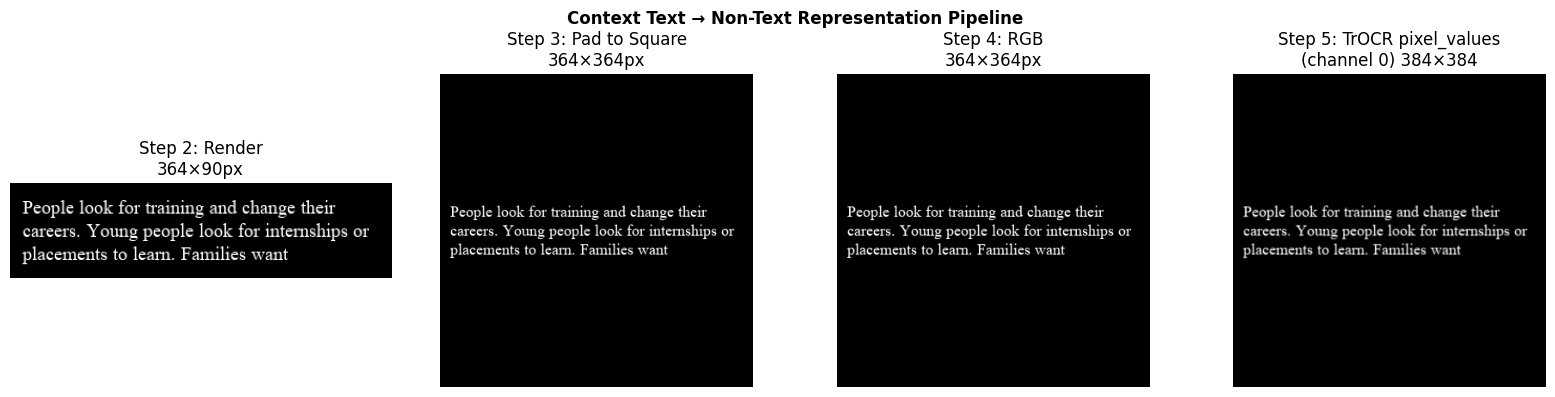

In [4]:
# Visualise the full preprocessing pipeline for one sample
row = train_df.iloc[0]
ctx_text = str(row['context'])
tgt_text = str(row['target'])
max_w    = int(row['max_width'])
lang     = str(row['language'])

# Step 1: raw text
print(f'[{lang}]')
print(f'Context (last 60 chars): ...{ctx_text[-60:]}')
print(f'Target:                  {tgt_text}')
print(f'max_width: {max_w}px')

# Step 2: render
from dataset import _pad_to_square, _to_rgb
gray_img = render_text_to_image(ctx_text, max_w,
                                config['render_font_size'],
                                config['render_padding'])

# Step 3: pad to square
sq_img = _pad_to_square(gray_img)

# Step 4: RGB
rgb_img = _to_rgb(sq_img)

# Step 5: processor
enc = trocr_processor(images=rgb_img, return_tensors='pt')
pv  = enc['pixel_values'].squeeze(0)   # (3, 384, 384)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(gray_img, cmap='gray')
axes[0].set_title(f'Step 2: Render\n{gray_img.size[0]}×{gray_img.size[1]}px')
axes[0].axis('off')

axes[1].imshow(sq_img, cmap='gray')
axes[1].set_title(f'Step 3: Pad to Square\n{sq_img.size[0]}×{sq_img.size[1]}px')
axes[1].axis('off')

axes[2].imshow(rgb_img)
axes[2].set_title(f'Step 4: RGB\n{rgb_img.size[0]}×{rgb_img.size[1]}px')
axes[2].axis('off')

# Show one channel of normalised pixel_values
axes[3].imshow(pv[0].numpy(), cmap='gray')
axes[3].set_title(f'Step 5: TrOCR pixel_values\n(channel 0) 384×384')
axes[3].axis('off')

plt.suptitle('Context Text → Non-Text Representation Pipeline', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('model_dev_pipeline.png', dpi=120, bbox_inches='tight')
plt.show()


## 3. Training Design

### Tại sao joint training từ đầu?

Thử nghiệm frozen-decoder (Phase 1 cũ) cho thấy loss không giảm được dưới ~12.97 (≈ random baseline với vocab 250k). Nguyên nhân: lm_head của mT5 pretrained để đọc decoder hidden states — không phải encoder memory từ TrOCR. Khi decoder bị frozen, không có gradient path nào cho phép projection calibrate với lm_head → loss không giảm.

**Fix:** Train tất cả components cùng lúc từ đầu với learning rates khác nhau theo vai trò.

### Learning rate rationale (từ EDA + experiment)

| Component | Phase 1 LR | Phase 2 LR | Lý do |
|-----------|------------|------------|-------|
| Encoder (ViT) | 2e-5 | 1e-5 | Pretrained features cần preserve |
| Decoder + lm_head | 2e-4 | 1e-4 | Cần calibrate nhanh với memory mới |
| Projection | 5e-5 | 3e-5 | Grad norm ~127k với 3e-4 → overshoot |

### Cosine Warmup vs OneCycleLR

OneCycleLR decay lr về gần 0 sau 3–4 epochs với 5 epoch total → model không học được ở cuối. Cosine decay + linear warmup giữ lr ở vùng có ích lâu hơn.

### Scheduled Sampling (Phase 2)

Teacher forcing 100% → model không học handle lỗi của chính nó (exposure bias). Phase 2 anneal `tf_ratio` từ 1.0 → 0.70: 30% positions dùng model's own prediction làm input thay vì ground truth.


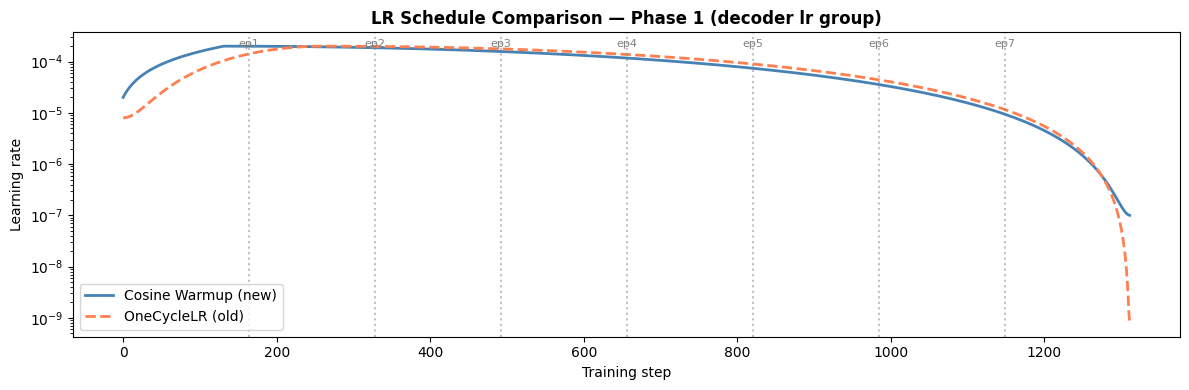

OneCycleLR final lr: 8.00e-10  (≈ dead)
CosineWarmup final lr: 1.00e-07  (still alive at eta_min)


In [5]:
# Visualise LR schedule: cosine warmup vs OneCycleLR comparison
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR, OneCycleLR

n_batches = 164   # approx batches per epoch with 1306 train / batch_size=8
p1_ep = config['phase1_epochs']
p2_ep = config['phase2_epochs']
total_steps_p1 = n_batches * p1_ep

dummy_params = [torch.nn.Parameter(torch.tensor(1.0))]

# Cosine warmup
opt_cos = AdamW(dummy_params, lr=2e-4)
warmup_steps = int(total_steps_p1 * 0.1)
decay_steps  = total_steps_p1 - warmup_steps
w = LinearLR(opt_cos, start_factor=0.1, end_factor=1.0, total_iters=warmup_steps)
c = CosineAnnealingLR(opt_cos, T_max=decay_steps, eta_min=1e-7)
sch_cos = SequentialLR(opt_cos, schedulers=[w, c], milestones=[warmup_steps])

# OneCycleLR
opt_one = AdamW(dummy_params, lr=2e-4)
sch_one = OneCycleLR(opt_one, max_lr=2e-4, total_steps=total_steps_p1, pct_start=0.2)

lrs_cos, lrs_one = [], []
for _ in range(total_steps_p1):
    lrs_cos.append(opt_cos.param_groups[0]['lr'])
    lrs_one.append(opt_one.param_groups[0]['lr'])
    sch_cos.step(); sch_one.step()

fig, ax = plt.subplots(figsize=(12, 4))
steps = range(total_steps_p1)
ax.plot(steps, lrs_cos, label='Cosine Warmup (new)', color='steelblue', linewidth=2)
ax.plot(steps, lrs_one, label='OneCycleLR (old)', color='coral', linewidth=2, linestyle='--')

# Mark epoch boundaries
for ep in range(1, p1_ep):
    ax.axvline(ep * n_batches, color='gray', linestyle=':', alpha=0.5)
    ax.text(ep * n_batches, max(lrs_one)*0.95, f'ep{ep}', fontsize=8, ha='center', color='gray')

ax.set_title('LR Schedule Comparison — Phase 1 (decoder lr group)', fontweight='bold')
ax.set_xlabel('Training step')
ax.set_ylabel('Learning rate')
ax.legend()
ax.set_yscale('log')
plt.tight_layout()
plt.savefig('model_dev_lr_schedule.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'OneCycleLR final lr: {lrs_one[-1]:.2e}  (≈ dead)')
print(f'CosineWarmup final lr: {lrs_cos[-1]:.2e}  (still alive at eta_min)')


## 4. Forward Pass Sanity Check
Xác nhận model forward pass không crash và loss có finite value.

In [6]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_ds, batch_size=config['batch_size'],
                          shuffle=True, num_workers=0)
val_loader   = DataLoader(val_ds, batch_size=config['batch_size'],
                          shuffle=False, num_workers=0)

# One forward pass
model.eval()
batch = next(iter(train_loader))
pv = batch['pixel_values'].to(device)
li = batch['lang_id'].to(device)
mw = batch['max_width'].to(device)
lb = batch['labels'].to(device)

with torch.no_grad():
    loss, stats = model(pv, li, mw, lb, patch_drop=0.0, return_stats=True)

print('Forward pass OK')
print(f'  Batch size:        {pv.shape[0]}')
print(f'  pixel_values:      {pv.shape}')
print(f'  labels:            {lb.shape}')
print(f'  Loss:              {loss.item():.4f}  (expected ~ln(250k)={torch.tensor(250112).float().log():.2f} at random)')
print(f'  Loss is finite:    {torch.isfinite(loss).item()}')
print(f'  Attn entropy:      {stats.get("attn_entropy", "n/a")}')

# Encoder output shape
memory = model.encode(pv, li, mw, patch_drop=0.0)
print(f'  Encoder memory:    {memory.shape}  (B, n_patches+1, d_model)')
print(f'  Memory norm/tok:   {memory.norm(dim=-1).mean().item():.4f}')


Forward pass OK
  Batch size:        8
  pixel_values:      torch.Size([8, 3, 384, 384])
  labels:            torch.Size([8, 128])
  Loss:              13.1395  (expected ~ln(250k)=12.43 at random)
  Loss is finite:    True
  Attn entropy:      0.08294241409748793
  Encoder memory:    torch.Size([8, 579, 512])  (B, n_patches+1, d_model)
  Memory norm/tok:   287.9870


## 5. Target Token Analysis
Phân tích distribution của target tokens để hiểu generation task.


=== TARGET TOKEN STATISTICS ===
Total tokens:      23,219
Unique tokens:     4,590  out of vocab 250,100
Token seq length:  min=5  max=44  mean=16.0
95th percentile:   25 tokens
99th percentile:   32 tokens

Top 20 tokens:
  id=   259  count= 2757  token='▁'
  id=   260  count= 1538  token='.'
  id=     1  count= 1450  token='</s>'
  id=   261  count=  777  token=','
  id=   263  count=  599  token='s'
  id=   305  count=  462  token='▁and'
  id=   265  count=  320  token='e'
  id=   287  count=  252  token='▁the'
  id=   262  count=  211  token='a'
  id=   288  count=  201  token='▁to'
  id=   281  count=  152  token='▁in'
  id=   276  count=  144  token='y'
  id=   278  count=  137  token='en'
  id=   472  count=  136  token='▁und'
  id=   269  count=  133  token='▁de'
  id=   283  count=  127  token='▁la'
  id=   266  count=  121  token='i'
  id=   383  count=  113  token='▁et'
  id=   520  count=  113  token='▁les'
  id=   299  count=   97  token='es'


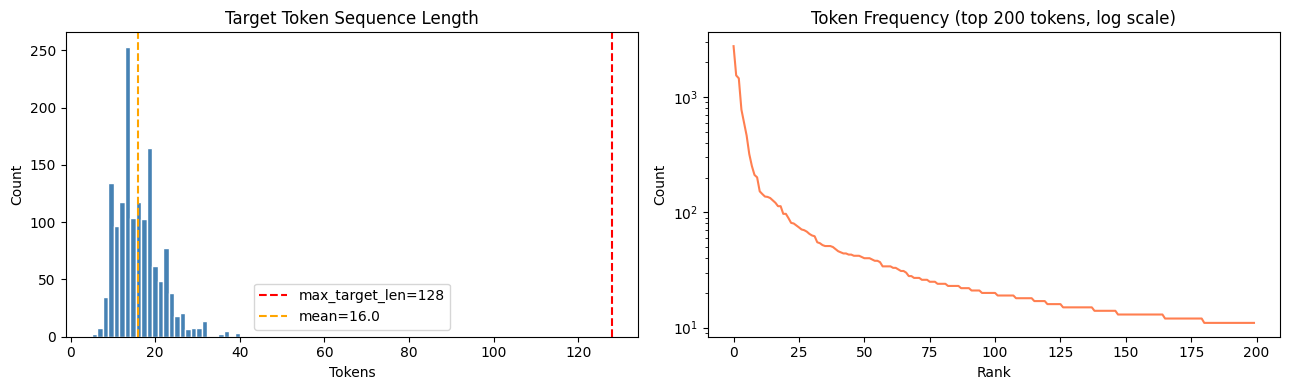


Samples covered by max_target_len=128: 100.0%


In [7]:
# Tokenise all targets and analyse token distribution
all_token_ids = []
all_lengths   = []

for _, row in df.iterrows():
    enc = mt5_tokenizer(str(row['target']), add_special_tokens=True)
    ids = enc['input_ids']
    all_token_ids.extend(ids)
    all_lengths.append(len(ids))

from collections import Counter
token_counts = Counter(all_token_ids)
top_tokens = token_counts.most_common(20)

print('=== TARGET TOKEN STATISTICS ===')
print(f'Total tokens:      {len(all_token_ids):,}')
print(f'Unique tokens:     {len(token_counts):,}  out of vocab {mt5_tokenizer.vocab_size:,}')
print(f'Token seq length:  min={min(all_lengths)}  max={max(all_lengths)}  mean={np.mean(all_lengths):.1f}')
print(f'95th percentile:   {int(np.percentile(all_lengths, 95))} tokens')
print(f'99th percentile:   {int(np.percentile(all_lengths, 99))} tokens')
print()
print('Top 20 tokens:')
for tok_id, cnt in top_tokens:
    tok_str = mt5_tokenizer.convert_ids_to_tokens([tok_id])[0]
    print(f'  id={tok_id:6d}  count={cnt:5d}  token={repr(tok_str)}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(all_lengths, bins=30, color='steelblue', edgecolor='white')
axes[0].axvline(config['max_target_len'], color='red', linestyle='--',
                label=f'max_target_len={config["max_target_len"]}')
axes[0].axvline(np.mean(all_lengths), color='orange', linestyle='--',
                label=f'mean={np.mean(all_lengths):.1f}')
axes[0].set_title('Target Token Sequence Length')
axes[0].set_xlabel('Tokens')
axes[0].set_ylabel('Count')
axes[0].legend()

# Token frequency (log scale)
freqs = sorted(token_counts.values(), reverse=True)[:200]
axes[1].plot(freqs, color='coral')
axes[1].set_title('Token Frequency (top 200 tokens, log scale)')
axes[1].set_xlabel('Rank')
axes[1].set_ylabel('Count')
axes[1].set_yscale('log')

plt.tight_layout()
plt.savefig('model_dev_tokens.png', dpi=120, bbox_inches='tight')
plt.show()

pct_covered = sum(1 for l in all_lengths if l <= config['max_target_len']) / len(all_lengths) * 100
print(f'\nSamples covered by max_target_len={config["max_target_len"]}: {pct_covered:.1f}%')


## 6. Baseline: Untrained Model Generation
Xem output của model chưa train để có reference point.


In [8]:
# Sample 5 predictions from untrained model
model.eval()
sample_rows = val_df.sample(5, random_state=0).reset_index(drop=True)

print('UNTRAINED MODEL PREDICTIONS (baseline):')
print('-' * 70)
for i, row in sample_rows.iterrows():
    s   = val_ds[val_df.index.get_loc(row.name) if hasattr(val_df.index, 'get_loc') else i]
    pv  = s['pixel_values'].unsqueeze(0).to(device)
    li  = s['lang_id'].unsqueeze(0).to(device)
    mw  = s['max_width'].unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model.generate(pv, li, mw, mt5_tokenizer, config)[0]

    true_ids = s['labels'].clone()
    true_ids[true_ids == -100] = mt5_tokenizer.pad_token_id
    true = mt5_tokenizer.decode(true_ids, skip_special_tokens=True)

    print(f'[{row["language"]:>8s}]  TRUE: {true[:60]}')
    print(f'           PRED: {pred[:60]}')
    print()


UNTRAINED MODEL PREDICTIONS (baseline):
----------------------------------------------------------------------
[ Spanish]  TRUE: ognigiorno si possa migliorare la vita di tutti.
           PRED: ريانDeixłaszczenomencanceldæmίτηريانodstawdæmæste◃ريان군산군산Si

[  French]  TRUE: notices about shelters, safe places, and distribution schedu
           PRED: dæmłaszcz腿ercegovin⌣язьəbər군산군산无广告dæmächerlätzeodstaw勒蕤倨Deix

[ English]  TRUE: libero. Le aziende possono competere tra loro.
           PRED: ավերンシャルdæmrackbackodstawdæmンシャルավերcancelավեր刹ンシャルttelseンシャ

[ Spanish]  TRUE: also develop public transport to pollute less.
           PRED: 霁язь40%60%dæmンシャル消すenomenrackbackodstaw瘫язьமைச்சரłaszcz旦nómi

[ English]  TRUE: looks for simple solutions.
           PRED: dæmDeixավերريانンシャル倍ヒダآي刹dæmodamiőpontæsteязьэгч군산군산rackback



## 7. Evaluation Metric

Competition dùng OCR-based character similarity. Pipeline:
1. Pixel coordinates → reconstruct image
2. OCR extract text từ image
3. Character-level similarity với ground truth

Vì render function là deterministic, nếu predicted text đúng → OCR đọc ra đúng → score cao.

Metric local chúng ta dùng là **Character Error Rate (CER)**:
```
CER = (mismatched_chars + length_difference) / max(len(true), len(pred))
```
CER = 0 là perfect, CER = 1 là hoàn toàn sai. Competition score ≈ 1 - CER.


In [9]:
def cer(true: str, pred: str) -> float:
    if max(len(true), len(pred)) == 0:
        return 0.0
    mismatch = sum(a != b for a, b in zip(true, pred)) + abs(len(true) - len(pred))
    return mismatch / max(len(true), len(pred))

# Demo với untrained predictions
print('CER demonstration (untrained model):')
demo_pairs = [
    ('come in large numbers, and fast trains make travel easier.',
     'and the of'),
    ('come in large numbers, and fast trains make travel easier.',
     'come in large numbers, and fast trains make travel easier.'),
    ('come in large numbers, and fast trains make travel easier.',
     'come in large numbers, and fast trains make travel faster.'),
]
for true, pred in demo_pairs:
    c = cer(true, pred)
    print(f'  CER={c:.3f}  true="{true[:40]}"  pred="{pred[:40]}"')


CER demonstration (untrained model):
  CER=0.983  true="come in large numbers, and fast trains m"  pred="and the of"
  CER=0.000  true="come in large numbers, and fast trains m"  pred="come in large numbers, and fast trains m"
  CER=0.034  true="come in large numbers, and fast trains m"  pred="come in large numbers, and fast trains m"


## 8. Training

Chạy `train.py` để train model. Notebook này dùng để document và visualise — training nặng chạy riêng.

```bash
# Xóa checkpoint cũ nếu có (architecture đã thay đổi)
rm -rf outputs_trocr_mt5/

# Train
python train.py
```

### Monitoring signals

| Signal | Healthy | Warning |
|--------|---------|---------|
| train loss ep1 | < 10.0 | ≥ 12.0 (random) |
| train loss ep3 | < 5.0 | > 7.0 |
| attn_entropy | < 3.0 | > 4.5 |
| grad proj | 1–100 | > 1000 |
| pred output | real words | `. , s and the` |


In [10]:
# Sau khi train xong, load best checkpoint và evaluate
import os

final_dir = os.path.join(config['output_dir'], 'final_model')
weights_path = os.path.join(final_dir, 'model_weights.pt')

if os.path.exists(weights_path):
    model.load_state_dict(
        torch.load(weights_path, map_location=device, weights_only=True)
    )
    print(f'Loaded weights from {weights_path}')
    model.eval()
else:
    print(f'No weights found at {weights_path}')
    print('Run train.py first, then re-run this cell.')


No weights found at outputs_trocr_mt5\final_model\model_weights.pt
Run train.py first, then re-run this cell.


## 9. Post-Training Evaluation
Chạy sau khi có trained model.

In [11]:
# Generation metrics on validation set (run after training)
if os.path.exists(weights_path):
    from train import generation_metrics, print_generation_metrics

    print('Computing generation metrics on validation set...')
    gen_m = generation_metrics(model, val_df, val_ds, mt5_tokenizer, config, device, n=50)
    print_generation_metrics(gen_m)

    # Sample predictions
    print('\nSample predictions:')
    print('-' * 70)
    for i in range(min(8, len(val_ds))):
        s    = val_ds[i]
        pv_  = s['pixel_values'].unsqueeze(0).to(device)
        li_  = s['lang_id'].unsqueeze(0).to(device)
        mw_  = s['max_width'].unsqueeze(0).to(device)

        with torch.no_grad():
            pred = model.generate(pv_, li_, mw_, mt5_tokenizer, config)[0]

        true_ids = s['labels'].clone()
        true_ids[true_ids == -100] = mt5_tokenizer.pad_token_id
        true = mt5_tokenizer.decode(true_ids, skip_special_tokens=True)
        lang = ID2LANG[s['lang_id'].item()]

        c = cer(true, pred)
        print(f'[{lang:>8s}] CER={c:.3f}')
        print(f'  TRUE: {true[:70]}')
        print(f'  PRED: {pred[:70]}')
        print()
else:
    print('Train model first, then run this cell.')


Train model first, then run this cell.


## 10. Render Predictions & Generate Submission
Sau khi có trained model, chạy `inference.py`.
```bash
python inference.py
```
Output: `data/pixels.npz` + `submission.csv` → zip và upload lên Kaggle.

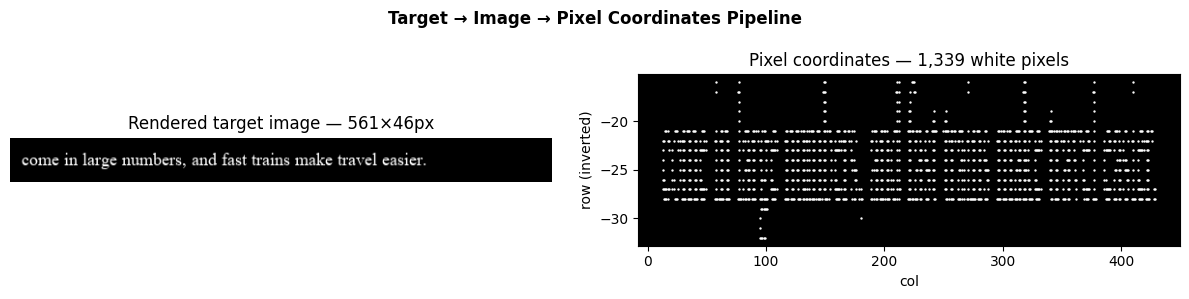

Pixels array shape: (1339, 3)
Columns: (sample_id, row, col)
Sample rows:
[[  0  16  58]
 [  0  16  77]
 [  0  16 149]
 [  0  16 150]
 [  0  16 211]]


In [12]:
# Preview: render one predicted target and show pixel output
sample_true  = 'come in large numbers, and fast trains make travel easier.'
sample_width = 561

pred_img = render_target_to_image(sample_true, sample_width,
                                  config['render_font_size'],
                                  config['render_padding'])
pixels   = image_to_pixels(pred_img, sample_id=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].imshow(pred_img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f'Rendered target image — {pred_img.size[0]}×{pred_img.size[1]}px')
axes[0].axis('off')

axes[1].scatter(pixels[:, 2], -pixels[:, 1], s=0.5, color='white')
axes[1].set_facecolor('black')
axes[1].set_title(f'Pixel coordinates — {len(pixels):,} white pixels')
axes[1].set_xlabel('col')
axes[1].set_ylabel('row (inverted)')

plt.suptitle('Target → Image → Pixel Coordinates Pipeline', fontweight='bold')
plt.tight_layout()
plt.savefig('model_dev_render_pixels.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Pixels array shape: {pixels.shape}')
print(f'Columns: (sample_id, row, col)')
print(f'Sample rows:')
print(pixels[:5])
